# Proyecto final de Química Orgánica — Análisis gráfico: **Ácidos carboxílicos**
**Fuente de datos:** CAS SciFinder

## 1. Librerías, estilo y carga del archivo

In [5]:
import os, shutil
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import plotly.express as px

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

from matplotlib import font_manager
sns.set_theme(style='white', font_scale=1.0)
instaladas = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = [f for f in ['Liberation Sans Narrow', 'Liberation Sans'] if f in instaladas] + ['DejaVu Sans']
plt.rcParams.update({
    'font.family': FUENTE,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#EDEDED', 'grid.linewidth': 0.6,
    'savefig.dpi': 300, 'figure.dpi': 100,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})

COL_VAR = {'PM': '#5B4A8B', 'Pf': '#B07A8C', 'Peb': '#C9A227', 'ρ': '#7FA37A', 'Pv': '#9A9A9A', 'μ': '#3F6E8C', 'Sol': '#4F8A63'}
COL_CONJ = {'Reacciones': '#5B4A8B', 'Obtenciones': '#C9A227'}
COL_MEDIO = {'Ácido': '#B07A8C', 'Básico': '#5B4A8B', 'Neutro': '#B3B3B3', 'Apolar': '#7FA37A'}
COL_SI = {'cat': '#4D4D4D', 'calor': '#D9825B'}
GRIS = '#9E9E9E'
DIV = LinearSegmentedColormap.from_list('div', ['#8A7BB0', '#E5E5E5', '#C9A227'])
SEQ = sns.light_palette('#5B4A8B', as_cmap=True)

CARPETA = 'figuras_acidos'
os.makedirs(CARPETA, exist_ok=True)

URL = 'https://github.com/Andreajime/quimica-organica-acidos/blob/Tabla-de-datos/tabla_acidos.xlsx'
URL = URL.replace('github.com', 'raw.githubusercontent.com').replace('/blob/', '/')
ARCHIVO = 'tabla_acidos.xlsx'
urllib.request.urlretrieve(URL, ARCHIVO)
print('Archivo descargado de GitHub:', URL)

Archivo descargado de GitHub: https://raw.githubusercontent.com/Andreajime/quimica-organica-acidos/Tabla-de-datos/tabla_acidos.xlsx


## 2. Lectura y revisión de los datos
La tabla ya viene organizada desde Excel, los datos que no se encontraron están escritos como NA (no aplica) y pandas los lee como vacíos (NaN)).

Aquí se verifica: se quitan espacios, se fuerza el tipo numérico y se cuentan los datos faltantes.

In [ ]:
hojas = pd.read_excel(ARCHIVO, sheet_name=None)
sus, rea, obt = hojas['Sustancias'], hojas['Reacciones'], hojas['Obtenciones']

NUM = ['PM (g/mol)', 'Pf (°C)', 'Peb (°C)', 'ρ (g/cm³)', 'pKa', 'μ (D)', 'Solubilidad (mol/L)', 'Pv (Pa)',
       'T (°C)', 't (h)', 'P (bar)']
for df in (sus, rea, obt):
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].str.strip()
    for col in NUM:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

CORTO = {'PM (g/mol)': 'PM', 'Pf (°C)': 'Pf', 'Peb (°C)': 'Peb', 'ρ (g/cm³)': 'ρ', 'pKa': 'pKa', 'μ (D)': 'μ',
         'Solubilidad (mol/L)': 'Sol', 'Pv (Pa)': 'Pv', 'T (°C)': 'T', 't (h)': 't', 'P (bar)': 'P'}
sus, rea, obt = (d.rename(columns=CORTO) for d in (sus, rea, obt))
UNIDAD = {'PM': 'PM (g/mol)', 'Pf': 'Pf (°C)', 'Peb': 'Peb (°C)', 'ρ': 'ρ (g/cm³)', 'pKa': 'pKa',
          'μ': 'μ (D)', 'Sol': 'Solubilidad (mol/L)', 'Pv': 'Pv (Pa)'}
PROPS = list(UNIDAD)

print('Filas:', {'Sustancias': len(sus), 'Reacciones': len(rea), 'Obtenciones': len(obt)})
print('\nCeldas vacías por columna numérica (NaN):')
print(pd.DataFrame({n: d[[c for c in PROPS + ['T', 't', 'P'] if c in d]].isna().sum()
                    for n, d in (('Sustancias', sus), ('Reacciones', rea), ('Obtenciones', obt))}))

Filas: {'Sustancias': 10, 'Reacciones': 188, 'Obtenciones': 147}

Celdas vacías por columna numérica (NaN):
     Sustancias  Reacciones  Obtenciones
P           NaN         183          135
PM          0.0          89           89
Peb         0.0         113           93
Pf          0.0         159          100
Pv          0.0         113           92
Sol         0.0         101           91
T           NaN          37           36
pKa         0.0         119          114
t           NaN          71           55
μ           2.0         156          134
ρ           0.0          99           91


In [ ]:
def por_reaccion(df, conj):
    p1 = df[df['Paso'] == 1].copy()
    p1['T_max'] = p1['ID'].map(df.groupby('ID')['T'].max())
    cat = df.filter(like='Catalizador').notna().any(axis=1)
    p1['Usa catalizador'] = p1['ID'].map(cat.groupby(df['ID']).any())
    p1['Conjunto'] = conj
    return p1

rx = por_reaccion(rea, 'Reacciones')
ob = por_reaccion(obt, 'Obtenciones')
ambos = pd.concat([rx, ob], ignore_index=True)

ORDEN = sus.sort_values('PM')['Sustancia'].tolist()
MEDIOS = [m for m in ['Ácido', 'Básico', 'Neutro', 'Apolar'] if m in set(ambos['Medio'].dropna())]
print('Reacciones:', len(rx), '| Obtenciones:', len(ob))
print('Orden por PM:', ORDEN)

def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan, np.nan
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    ancho = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return p, centro - ancho, centro + ancho

def guardar(fig, nombre):
    fig.savefig(f'{CARPETA}/{nombre}.png', bbox_inches='tight')

def regresion(d, x, y, ylab, titulo, nombre, grupo=None):
    res = stats.linregress(d[x], d[y])
    rp, pp = stats.pearsonr(d[x], d[y])
    rs, ps = stats.spearmanr(d[x], d[y])
    fig, ax = plt.subplots(figsize=(9, 5.8), constrained_layout=True)
    if grupo:
        sns.scatterplot(data=d, x=x, y=y, hue=grupo, palette=COL_CONJ, s=45, alpha=0.75, edgecolor='white', ax=ax)
    else:
        sns.scatterplot(data=d, x=x, y=y, color=COL_VAR[x], s=45, alpha=0.75, edgecolor='white', ax=ax)
    xs = np.linspace(d[x].min(), d[x].max(), 100)
    ax.plot(xs, res.intercept + res.slope * xs, color=COL_VAR[y], lw=1.8,
            label=f'y = {res.slope:.3g}x {res.intercept:+.3g}  (R² = {res.rvalue**2:.2f}, p = {res.pvalue:.1e})')
    ax.set_xlabel(UNIDAD[x]); ax.set_ylabel(ylab); ax.set_title(titulo)
    ax.legend(fontsize=8, frameon=False)
    guardar(fig, nombre); plt.show()
    print(f'n = {len(d)} | y = {res.slope:.4g}x {res.intercept:+.4g} | R² = {res.rvalue**2:.3f} | p = {res.pvalue:.2e}')
    print(f'Pearson r = {rp:.2f} (p = {pp:.1e}) | Spearman ρ = {rs:.2f} (p = {ps:.1e})')

Reacciones: 100 | Obtenciones: 100
Orden por PM: ['Ácido fórmico', 'Ácido acético', 'Ácido fluoroacético', 'Ácido butanoico', 'Ácido láctico', 'Ácido cloroacético', 'Ácido benzoico', 'Ácido málico', 'Ácido bromoacético', 'Ácido cítrico']


## 3. Análisis gráfico

### Gráfica 1. Mapa de calor de correlación entre propiedades

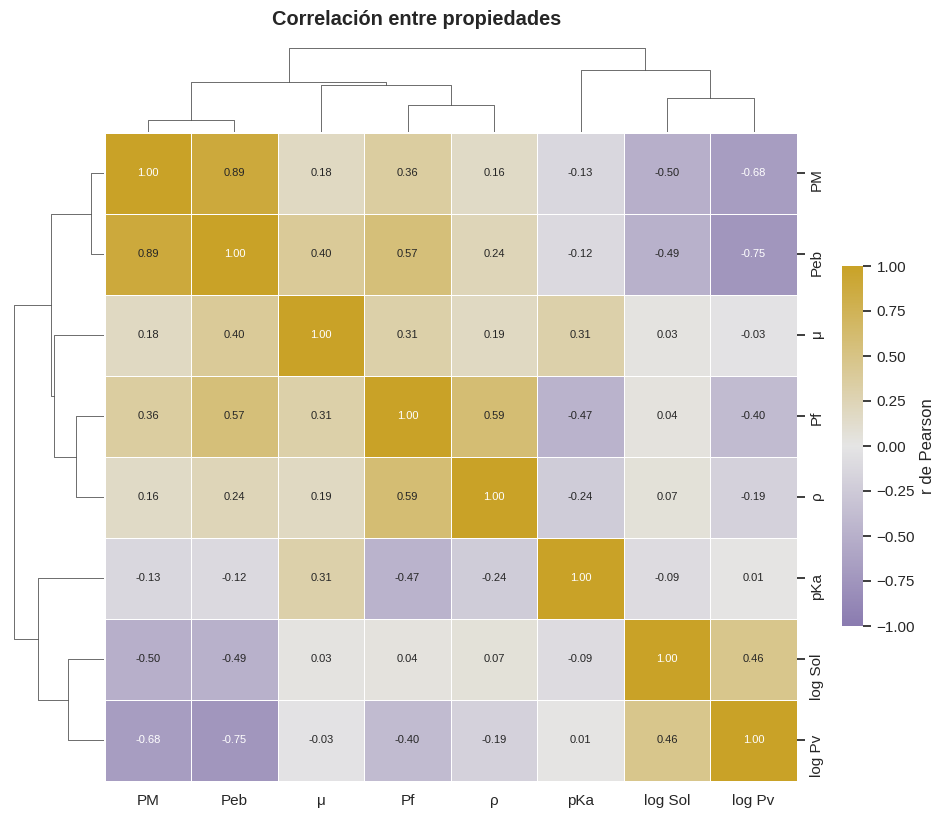

Número mínimo de compuestos por pareja: 28
Parejas más fuertes (|r|):
PM   Peb        0.89
Peb  log Pv    -0.75
PM   log Pv    -0.68
Pf   ρ          0.59
     Peb        0.57
PM   log Sol   -0.50


In [ ]:
comp = pd.concat([sus.rename(columns={'Sustancia': 'Nombre'}),
                  rx.rename(columns={'Producto': 'Nombre', 'CAS producto': 'CAS'}),
                  ob.rename(columns={'Reactante principal': 'Nombre', 'CAS reactante': 'CAS'})])
comp = comp.drop_duplicates(subset='CAS')[PROPS].copy()
comp['Pv'] = np.log10(comp['Pv'].where(comp['Pv'] > 0))
comp['Sol'] = np.log10(comp['Sol'].where(comp['Sol'] > 0))
comp = comp.rename(columns={'Pv': 'log Pv', 'Sol': 'log Sol'})

corr = comp.corr(method='pearson', min_periods=5)
n_par = comp.notna().astype(int).T @ comp.notna().astype(int)
sin_dato = corr.columns[corr.isna().any()]
if len(sin_dato):
    print('Se excluyen por falta de pares (n < 5):', list(sin_dato))
    corr = corr.drop(index=sin_dato, columns=sin_dato); n_par = n_par.loc[corr.index, corr.columns]

g = sns.clustermap(corr, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
                   annot_kws={'size': 8}, linewidths=0.6, linecolor='white', figsize=(8.5, 8),
                   dendrogram_ratio=0.12, cbar_pos=(1.0, 0.25, 0.025, 0.45),
                   cbar_kws={'label': 'r de Pearson'})
g.ax_heatmap.set_xlabel(''); g.ax_heatmap.set_ylabel('')
g.figure.suptitle('Correlación entre propiedades', y=1.02, fontweight='bold')
guardar(g.figure, '01_mapa_correlacion'); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print('Número mínimo de compuestos por pareja:', int(n_par.values.min()))
print('Parejas más fuertes (|r|):')
print(pares.reindex(pares.abs().sort_values(ascending=False).index).head(6).round(2).to_string())

**Tipo de gráfica.** Mapa de calor con dendrograma: muestra una matriz de valores con color y agrupa las propiedades que se comportan parecido, cada celda es un coeficiente de correlación y el color lo muestra; el dendrograma (las líneas de arriba y de la izquierda) une primero las propiedades que se comportan parecido. Escala divergente suave: el centro gris es r ≈ 0.

**Interpretación.** La relación más fuerte es PM–Peb (r = 0.89, n = 128), seguida de Peb–log Pv (−0.75) y PM–log Pv (−0.68): ácidos y derivados más grandes hierven más y se evaporan menos. Pf–ρ (0.59) indica que los sólidos con muchos grupos polares (–COOH, –OH) empacan mejor. PM–log Sol (−0.50) es más débil que en otros grupos porque los puentes de hidrógeno compensan el tamaño. pKa no se correlaciona con nada (|r| ≤ 0.47) y no se compara entre sustancias.

### Gráfica 2. Distribución de la temperatura máxima de reacción

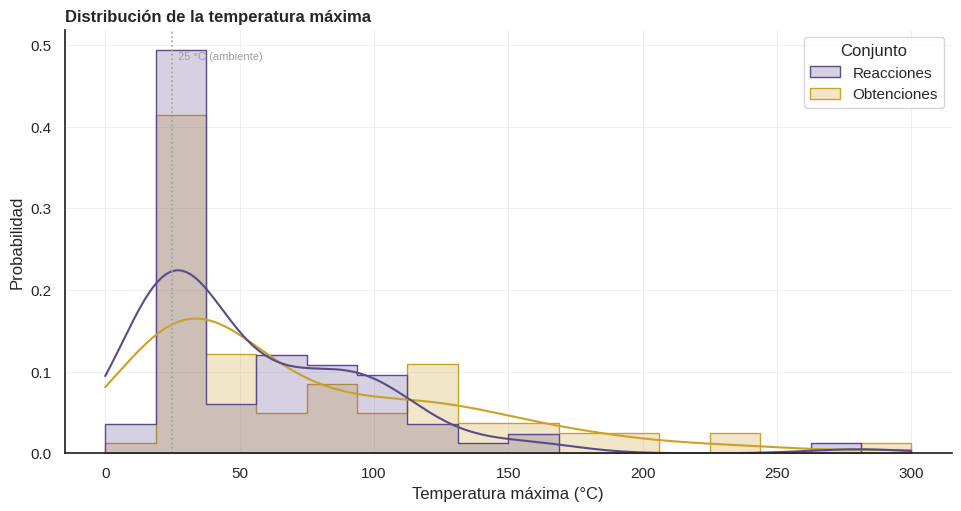

Obtenciones: n = 82 | mediana = 45 °C | P(T > 25 °C) = 0.68 [0.58–0.77] | sin T numérica: 18
Reacciones: n = 83 | mediana = 25 °C | P(T > 25 °C) = 0.49 [0.39–0.60] | sin T numérica: 17


In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 5), constrained_layout=True)
sns.histplot(data=ambos.dropna(subset=['T_max']), x='T_max', hue='Conjunto', palette=COL_CONJ, bins=16,
             stat='probability', common_norm=False, kde=True, element='step', alpha=0.25, ax=ax)
ax.axvline(25, color=GRIS, ls=':', lw=1.2); ax.text(27, ax.get_ylim()[1] * 0.93, '25 °C (ambiente)', fontsize=8, color=GRIS)
ax.set_xlabel('Temperatura máxima (°C)'); ax.set_ylabel('Probabilidad'); ax.set_title('Distribución de la temperatura máxima')
guardar(fig, '02_distribucion_temperatura'); plt.show()
for conj, g in ambos.groupby('Conjunto'):
    t = g['T_max'].dropna()
    p, lo, hi = wilson((t > 25).sum(), len(t))
    print(f'{conj}: n = {len(t)} | mediana = {t.median():.0f} °C | P(T > 25 °C) = {p:.2f} [{lo:.2f}–{hi:.2f}] | sin T numérica: {g["T_max"].isna().sum()}')

**Tipo de gráfica.** Histograma con curva de densidad: distribución de una variable numérica continua.

**Interpretación.** Las reacciones de los ácidos ocurren a menor temperatura (mediana 25 °C; P(T > 25 °C) = 0.49, IC 0.39–0.60) que sus obtenciones (mediana 45 °C; P = 0.68, IC 0.58–0.77): oxidar o hidrolizar para formar el –COOH suele necesitar calor. Casi todo está por debajo de 150 °C; los extremos son 280 °C (R-065, reducción del ácido láctico) y 300 °C (O-010).

### Gráfica 3. Temperatura según el medio (un panel por medio)

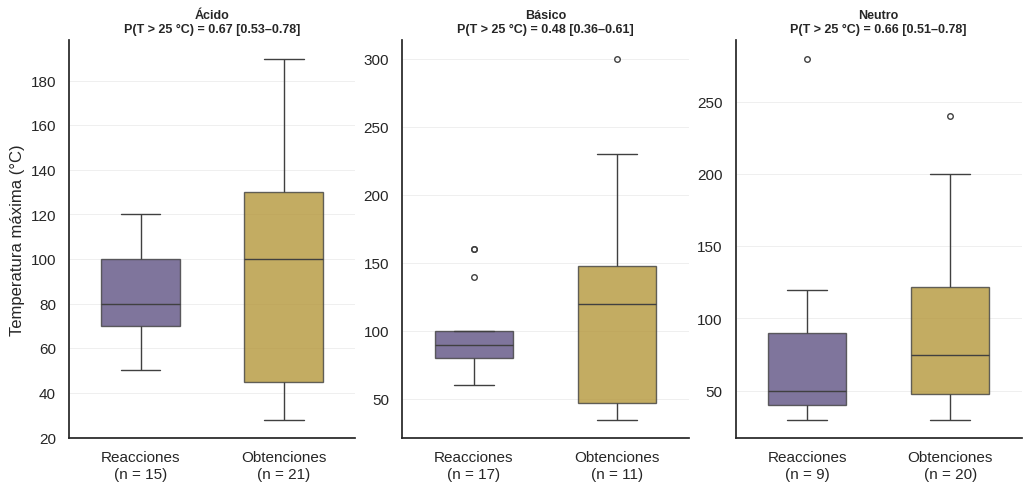

Datos por caja (T > 25 °C):
Conjunto  Obtenciones  Reacciones
Medio                            
Apolar              4           0
Básico             11          17
Neutro             20           9
Ácido              21          15
                    count    50%   min    max
Medio  Conjunto                              
Apolar Obtenciones    4.0   60.0  40.0   80.0
Básico Obtenciones   11.0  120.0  35.0  300.0
       Reacciones    17.0   90.0  60.0  160.0
Neutro Obtenciones   20.0   75.0  30.0  240.0
       Reacciones     9.0   50.0  30.0  280.0
Ácido  Obtenciones   21.0  100.0  28.0  190.0
       Reacciones    15.0   80.0  50.0  120.0


In [ ]:
conT = ambos.dropna(subset=['T_max'])
cal = conT[conT['T_max'] > 25]
n_caja = cal.groupby(['Medio', 'Conjunto']).size()
MED_T = [m for m in MEDIOS if n_caja.get(m, pd.Series()).max() >= 5]
fig, axs = plt.subplots(1, len(MED_T), figsize=(3.4 * len(MED_T), 4.8), constrained_layout=True)
for ax, m in zip(axs, MED_T):
    grupos = [g for g in ['Reacciones', 'Obtenciones'] if n_caja.get((m, g), 0) >= 5]
    d = cal[(cal['Medio'] == m) & cal['Conjunto'].isin(grupos)]
    sns.boxplot(data=d, x='Conjunto', y='T_max', order=grupos, hue='Conjunto', palette=COL_CONJ,
                width=0.55, fliersize=4, legend=False, boxprops={'alpha': 0.8}, ax=ax)
    ax.set_xticks(range(len(grupos)))
    ax.set_xticklabels([f'{g}\n(n = {n_caja[(m, g)]})' for g in grupos])
    todos = conT[conT['Medio'] == m]
    p, lo, hi = wilson((todos['T_max'] > 25).sum(), len(todos))
    ax.set_title(f'{m}\nP(T > 25 °C) = {p:.2f} [{lo:.2f}–{hi:.2f}]', fontsize=9, loc='center')
    ax.set_xlabel(''); ax.set_ylabel('Temperatura máxima (°C)' if m == MED_T[0] else '')
guardar(fig, '03_temperatura_por_medio'); plt.show()
print('Datos por caja (T > 25 °C):'); print(n_caja.unstack(fill_value=0))
print(cal.groupby(['Medio', 'Conjunto'])['T_max'].describe()[['count', '50%', 'min', 'max']].round(0).to_string())

**Tipo de gráfica.** Diagrama de caja con puntos: mediana, cuartiles y atípicos de una variable numérica por grupo; cada medio tiene su propio eje y.

**Interpretación.** Muchas reacciones son a 25 °C (ambiente) y esos valores iguales aplastaban las cajas. Por eso se filtró: la caja muestra solo las reacciones que se calientan (T > 25 °C) y solo si tiene al menos 5 datos; las de 25 °C se cuentan en P(T > 25 °C) del título. En medio ácido se calienta con frecuencia (P = 0.67) y la mediana es 80 °C en reacciones y 100 °C en obtenciones, como en la esterificación de Fischer, que se calienta para desplazar el equilibrio. En medio básico, cuando se calienta, las medianas son 90 y 120 °C, con atípicos de hasta 300 °C (O-010, hidrogenación de bicarbonato). En neutro las reacciones calentadas tienen mediana 50 °C y un atípico de 280 °C (R-065, hidrogenólisis del ácido láctico). El medio apolar no se dibuja porque ninguna de sus cajas llega a 5 datos.

### Gráfica 4. Líneas de doble eje: propiedades de las sustancias ordenadas por PM

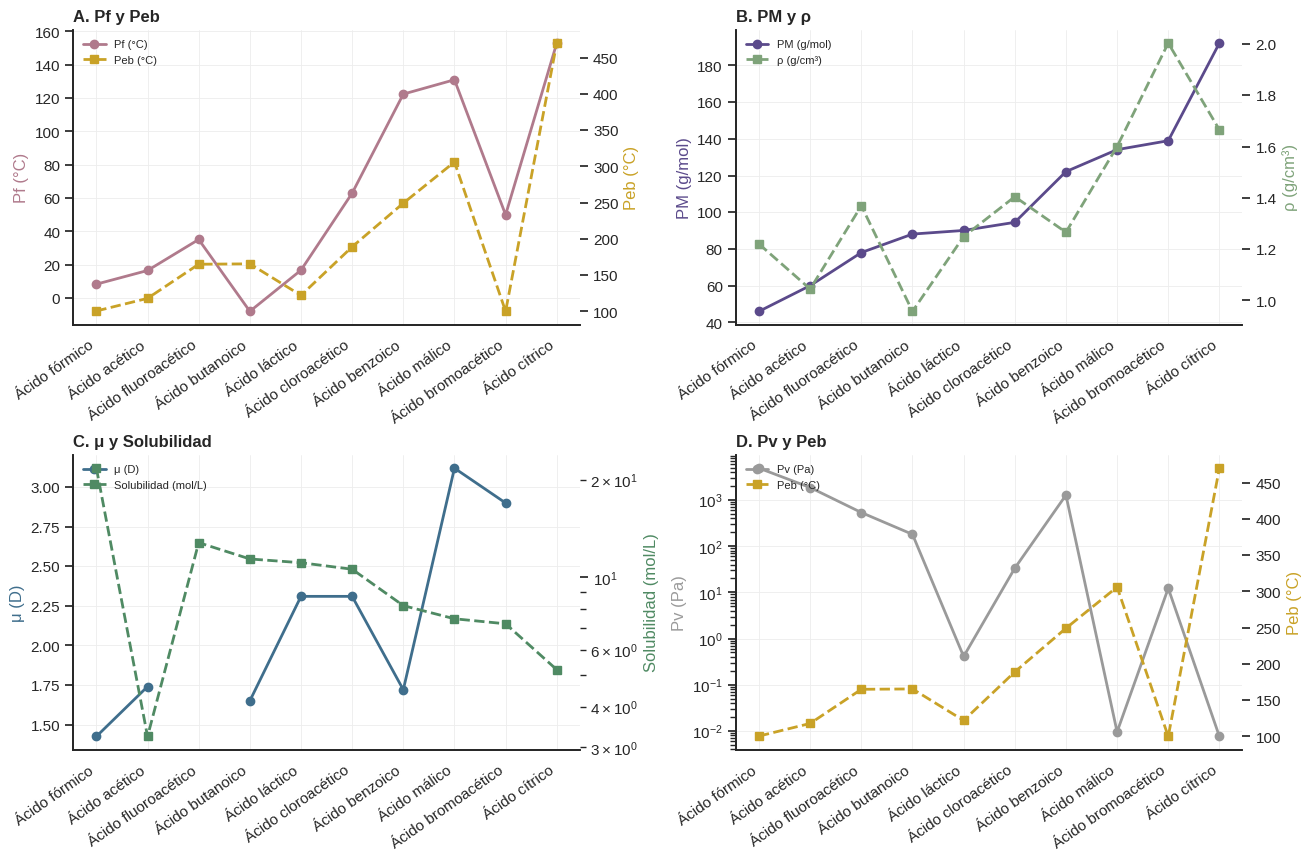

Pf–Peb: Spearman ρ = 0.70 (p = 0.025, n = 10)
PM–ρ: Spearman ρ = 0.82 (p = 0.004, n = 10)
μ–Sol: Spearman ρ = -0.61 (p = 0.108, n = 8)
Pv–Peb: Spearman ρ = -0.50 (p = 0.138, n = 10)


In [ ]:
PARES = [('Pf', 'Peb'), ('PM', 'ρ'), ('μ', 'Sol'), ('Pv', 'Peb')]
MARCA = {0: 'o', 1: 's'}
d = sus.set_index('Sustancia').loc[ORDEN]
fig, axs = plt.subplots(2, 2, figsize=(13, 8.5), constrained_layout=True); axs = axs.ravel()
for i, (a, b) in enumerate(PARES):
    ax = axs[i]
    ya = d[a] if a != 'Pv' else d[a]
    ax.plot(ORDEN, d[a], marker=MARCA[0], color=COL_VAR[a], lw=2, label=UNIDAD[a])
    ax.set_ylabel(UNIDAD[a], color=COL_VAR[a])
    ax2 = ax.twinx()
    ax2.plot(ORDEN, d[b], marker=MARCA[1], ls='--', color=COL_VAR[b], lw=2, label=UNIDAD[b])
    ax2.set_ylabel(UNIDAD[b], color=COL_VAR[b]); ax2.grid(False)
    for eje, var in ((ax, a), (ax2, b)):
        if var in ('Pv', 'Sol'):
            eje.set_yscale('log')
    ax.set_title(f'{chr(65 + i)}. {UNIDAD[a].split(" (")[0]} y {UNIDAD[b].split(" (")[0]}')
    lin = ax.get_legend_handles_labels(); lin2 = ax2.get_legend_handles_labels()
    ax.legend(lin[0] + lin2[0], lin[1] + lin2[1], loc='upper left', fontsize=8, frameon=False)
    ax.tick_params(axis='x', rotation=35)
    for et in ax.get_xticklabels(): et.set_ha('right')
guardar(fig, '04_doble_eje_propiedades'); plt.show()
for a, b in PARES:
    v = d[[a, b]].dropna()
    r, p = stats.spearmanr(v[a], v[b])
    print(f'{a}–{b}: Spearman ρ = {r:.2f} (p = {p:.3f}, n = {len(v)})')

**Tipo de gráfica.** Gráfico de líneas con doble eje: las dos propiedades tienen unidades y escalas distintas; el eje x es categórico ordenado (sustancias por PM).

**Interpretación.** **A:** Pf y Peb aumentan con el PM (ρ = 0.70, p = 0.025); el bromoacético rompe la tendencia por su Peb dudoso. **B:** densidad y PM crecen juntos (ρ = 0.82, p = 0.004); los halógenos suben la densidad (bromoacético 2.0). **C:** μ y solubilidad no tienen relación significativa (ρ = −0.61, p = 0.11, n = 8). **D:** Pv baja cuando sube el Peb, pero con n = 10 no es significativo (ρ = −0.50, p = 0.14).

### Gráfica 5. Mapa de calor de las propiedades normalizadas de las sustancias

Propiedades excluidas por datos faltantes: {'μ': 2}


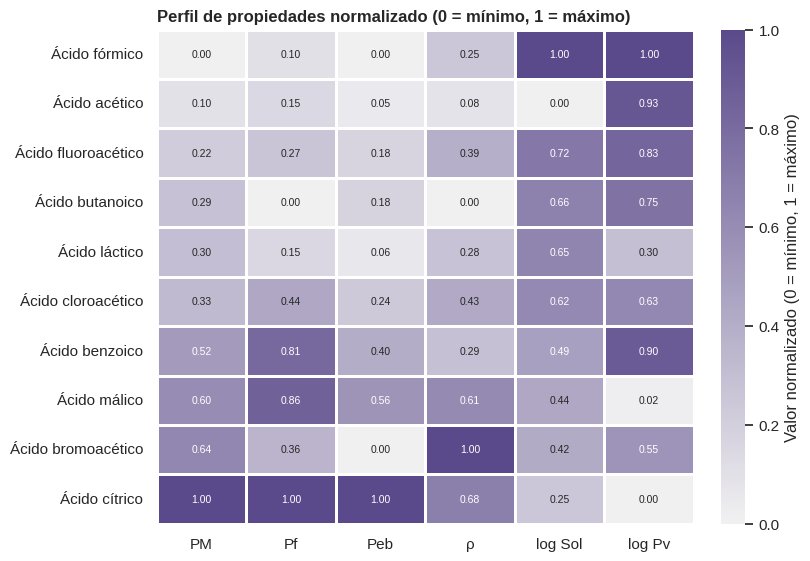

In [ ]:
m = sus.set_index('Sustancia')[[p for p in PROPS if p != 'pKa']].copy()
m['Pv'] = np.log10(m['Pv']); m['Sol'] = np.log10(m['Sol'])
faltan = m.isna().sum()
quitar_prop = faltan[faltan > 0].index.tolist()
m = m.drop(columns=quitar_prop)
print('Propiedades excluidas por datos faltantes:', {p: int(faltan[p]) for p in quitar_prop} or 'ninguna')

norm = (m - m.min()) / (m.max() - m.min())
norm = norm.loc[[s for s in ORDEN if s in norm.index]]
norm.columns = [{'Pv': 'log Pv', 'Sol': 'log Sol'}.get(x, x) for x in norm.columns]
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
sns.heatmap(norm, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Valor normalizado (0 = mínimo, 1 = máximo)'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title('Perfil de propiedades normalizado (0 = mínimo, 1 = máximo)')
guardar(fig, '05_propiedades_normalizadas'); plt.show()

**Tipo de gráfica.** Mapa de calor: compara muchas propiedades con unidades distintas en las 10 sustancias. Escala secuencial de claro (0) a oscuro (1).

**Interpretación.** Cada celda muestra el valor normalizado mín–máx: (x − mínimo) / (máximo − mínimo). La sustancia con el valor más bajo de una propiedad tiene 0, la más alta tiene 1 y las demás quedan en proporción; así se pueden comparar propiedades con unidades distintas. No es la normalización estadística de la campana (valor z), es solo un cambio de escala. El ácido cítrico tiene 1.00 en PM, Pf y Peb; el fórmico 1.00 en solubilidad y presión de vapor (log); el bromoacético 1.00 en densidad. Se excluyó μ porque falta en 2 ácidos.

### Gráfica 6. Polaridad y solubilidad: solubilidad en agua frente al peso molecular

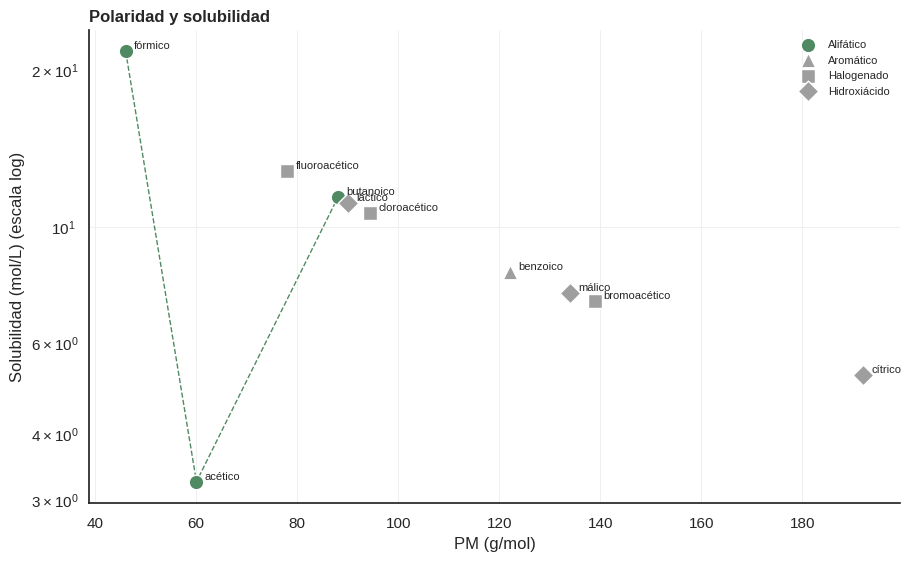

Spearman PM–Sol (10 ácidos): ρ = -0.56, p = 0.090


In [ ]:
GRUPO = {'Ácido fórmico': 'Alifático', 'Ácido acético': 'Alifático', 'Ácido butanoico': 'Alifático',
         'Ácido cloroacético': 'Halogenado', 'Ácido bromoacético': 'Halogenado', 'Ácido fluoroacético': 'Halogenado',
         'Ácido láctico': 'Hidroxiácido', 'Ácido málico': 'Hidroxiácido', 'Ácido cítrico': 'Hidroxiácido',
         'Ácido benzoico': 'Aromático'}
MARK = {'Alifático': 'o', 'Halogenado': 's', 'Hidroxiácido': 'D', 'Aromático': '^'}
d = sus.assign(Grupo=sus['Sustancia'].map(GRUPO))
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
for gr, sub in d.groupby('Grupo'):
    ax.scatter(sub['PM'], sub['Sol'], s=110, marker=MARK[gr], color=COL_VAR['Sol'] if gr == 'Alifático' else GRIS,
               edgecolor='white', label=gr, zorder=3)
ali = d[d['Grupo'] == 'Alifático'].sort_values('PM')
ax.plot(ali['PM'], ali['Sol'], color=COL_VAR['Sol'], lw=1, ls='--')
for _, f in d.iterrows():
    ax.annotate(f['Sustancia'].replace('Ácido ', ''), (f['PM'], f['Sol']), xytext=(6, 2),
                textcoords='offset points', fontsize=8)
ax.set_yscale('log')
ax.set_xlabel(UNIDAD['PM']); ax.set_ylabel(UNIDAD['Sol'] + ' (escala log)')
ax.set_title('Polaridad y solubilidad'); ax.legend(fontsize=8, frameon=False)
guardar(fig, '06_solubilidad_estructura'); plt.show()
r, p = stats.spearmanr(d['PM'], d['Sol'])
print(f'Spearman PM–Sol (10 ácidos): ρ = {r:.2f}, p = {p:.3f}')

**Tipo de gráfica.** Diagrama de dispersión: relación entre dos variables numéricas; la forma del marcador indica el grupo estructural.

**Interpretación.** En la serie alifática la solubilidad baja del fórmico (21.7 mol/L) al butanoico, porque la cadena hidrocarbonada no forma puentes de hidrógeno. Los hidroxiácidos (láctico, málico, cítrico) son más solubles de lo esperado para su PM gracias a los –OH extra. La correlación con PM no es significativa (Spearman ρ = −0.56, p = 0.09), y el valor del ácido acético (3.24 mol/L)

### Gráfica 7. Tendencia: peso molecular frente a punto de ebullición de los productos

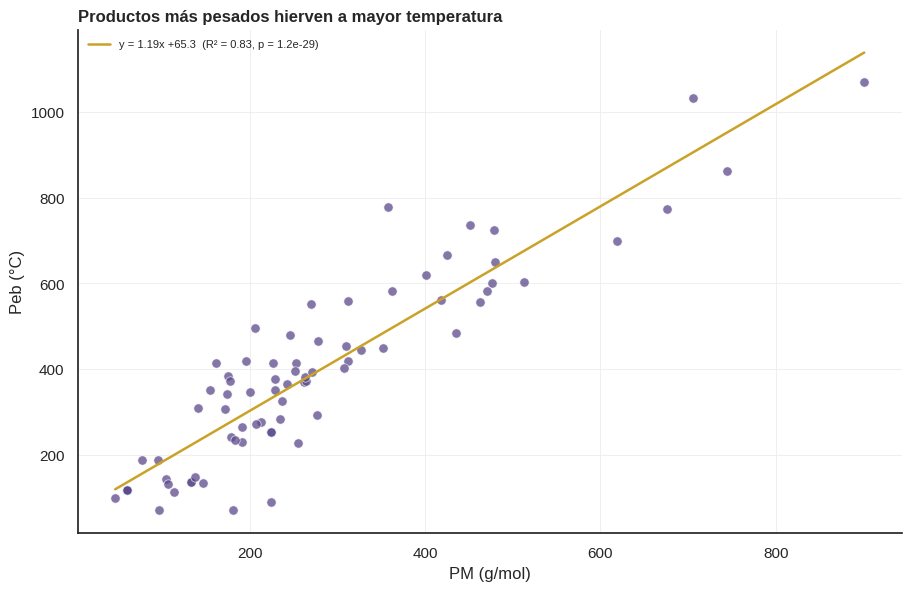

n = 75 | y = 1.191x +65.32 | R² = 0.828 | p = 1.17e-29
Pearson r = 0.91 (p = 1.2e-29) | Spearman ρ = 0.88 (p = 4.5e-25)


In [ ]:
d = rx.dropna(subset=['PM', 'Peb'])
regresion(d, 'PM', 'Peb', UNIDAD['Peb'], 'Productos más pesados hierven a mayor temperatura', '07_PM_vs_Peb', grupo=None)

**Tipo de gráfica.** Diagrama de dispersión con línea de regresión: dos variables numéricas.

**Interpretación.** Peb ≈ 1.19·PM + 65 (R² = 0.83, p = 1×10⁻²⁹, n = 75; Pearson 0.91, Spearman 0.88) por cada 100 g/mol el punto de ebullición sube unos 119 °C, porque las moléculas más grandes tienen más fuerzas de London y, en los ácidos y derivados, puentes de hidrógeno. R² = 0.83 significa que el PM explica el 83 % de la variación del Peb.



### Gráfica 8. Relación estructural: peso molecular frente a densidad de los productos

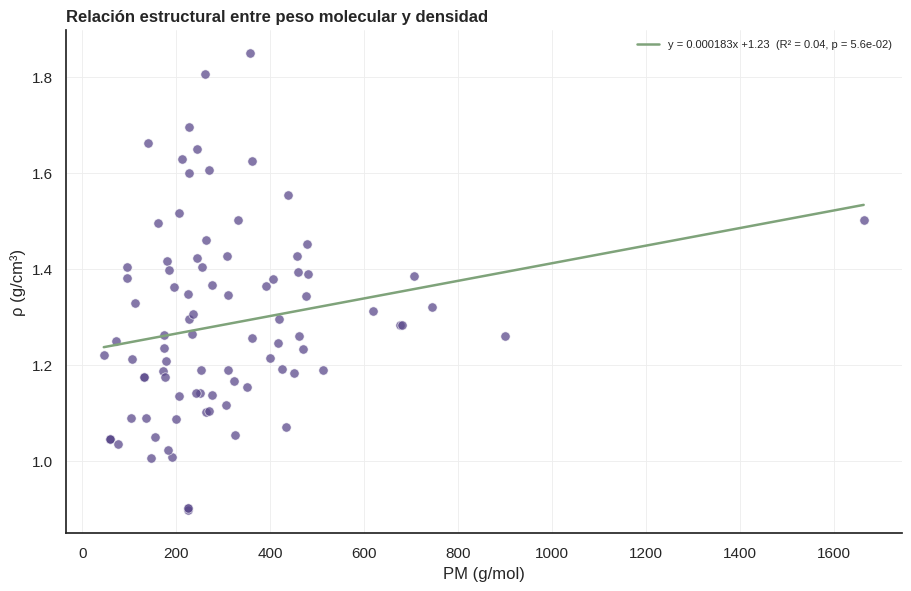

n = 89 | y = 0.0001833x +1.229 | R² = 0.041 | p = 5.59e-02
Pearson r = 0.20 (p = 5.6e-02) | Spearman ρ = 0.29 (p = 6.2e-03)


In [ ]:
d = rx.dropna(subset=['PM', 'ρ'])
regresion(d, 'PM', 'ρ', UNIDAD['ρ'], 'Relación estructural entre peso molecular y densidad', '08_PM_vs_densidad', grupo=None)

**Tipo de gráfica.** Diagrama de dispersión con línea de regresión.

**Interpretación.** Los puntos están muy dispersos y la recta es casi plana: R² = 0.04 (p = 0.056, n = 89), es decir, el peso molecular **no** explica la densidad de estos productos. La gráfica se deja para mostrar justamente eso: la densidad depende de qué átomos tiene la molécula (O, N, halógenos), no de su tamaño. Spearman (0.29, p = 0.006) muestra solo una tendencia muy leve.

### Gráfica 9. Volatilidad: punto de ebullición frente a presión de vapor

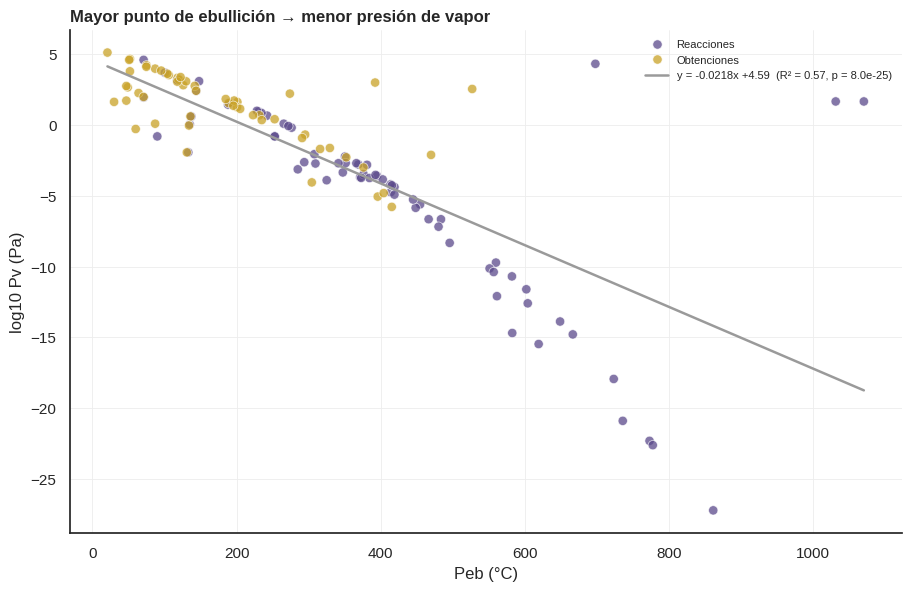

n = 128 | y = -0.02179x +4.586 | R² = 0.570 | p = 8.02e-25
Pearson r = -0.75 (p = 8.0e-25) | Spearman ρ = -0.81 (p = 4.8e-31)


In [ ]:
d = ambos.dropna(subset=['Peb', 'Pv'])
d = d[d['Pv'] > 0].assign(Pv=np.log10(d['Pv'][d['Pv'] > 0]))
regresion(d, 'Peb', 'Pv', 'log10 Pv (Pa)', 'Mayor punto de ebullición → menor presión de vapor', '09_Peb_vs_Pv', grupo='Conjunto')

**Tipo de gráfica.** Diagrama de dispersión con línea de tendencia; Pv en log10 porque abarca muchos órdenes de magnitud.

**Interpretación.** log Pv = −0.022·Peb + 4.59 (R² = 0.57, Pearson −0.75, Spearman −0.81, n = 128): cada 100 °C más de Peb la presión de vapor baja unas 160 veces (2.2 unidades de log). Las dos miden la misma cosa: la energía para separar las moléculas. La relación es menos lineal que en otros grupos porque los ácidos forman dímeros por puentes de hidrógeno.

### Gráfica 10. Comparación de distribuciones: reactivos (obtenciones) frente a productos (reacciones)

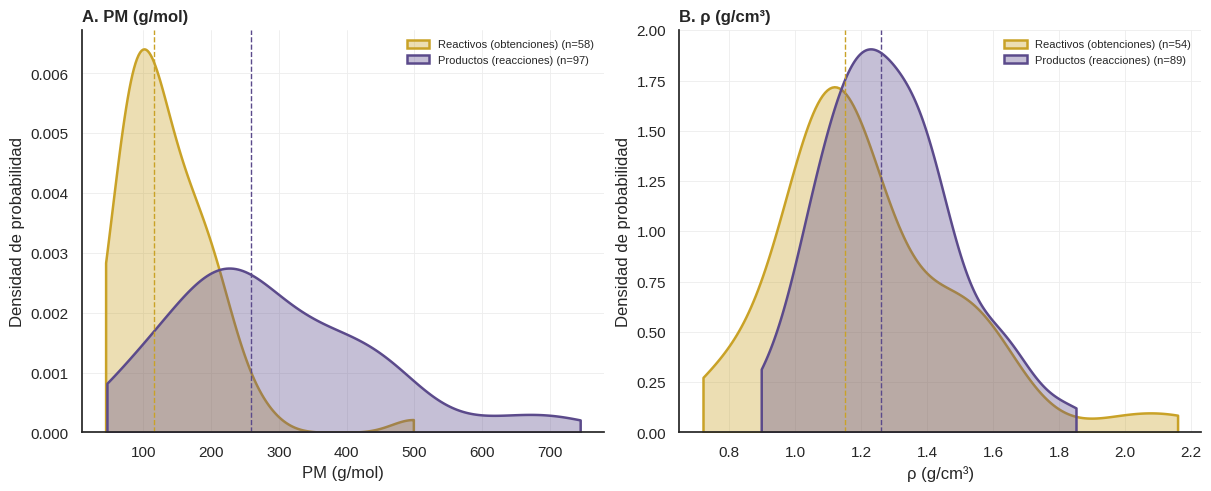

PM: mediana reactivos = 116 | productos = 261 | Mann-Whitney p = 1.37e-12
ρ: mediana reactivos = 1.17 | productos = 1.26 | Mann-Whitney p = 6.46e-02


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, var in zip(axs, ['PM', 'ρ']):
    tope = ambos[var].quantile(0.97) * 1.2
    for conj, et in (('Obtenciones', 'Reactivos (obtenciones)'), ('Reacciones', 'Productos (reacciones)')):
        v = ambos.loc[(ambos['Conjunto'] == conj) & (ambos[var] <= tope), var].dropna()
        sns.kdeplot(v, fill=True, alpha=0.35, color=COL_CONJ[conj], lw=1.8, cut=0, ax=ax, label=f'{et} (n={len(v)})')
        ax.axvline(v.median(), color=COL_CONJ[conj], ls='--', lw=1)
    ax.set_xlabel(UNIDAD[var]); ax.set_ylabel('Densidad de probabilidad'); ax.legend(fontsize=8, frameon=False)
    ax.set_title(f'{chr(65 + list(axs).index(ax))}. {UNIDAD[var]}')
guardar(fig, '10_reactivos_vs_productos'); plt.show()
for var in ['PM', 'ρ']:
    a = ob[var].dropna(); b = rx[var].dropna()
    print(f'{var}: mediana reactivos = {a.median():.3g} | productos = {b.median():.3g} | Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.2e}')

**Tipo de gráfica.** Gráfico de densidad (*Density Plot*): compara la forma de dos distribuciones numéricas; la línea punteada es la mediana.

**Interpretación.** Los productos son mucho más pesados que los reactivos de obtención (mediana 261 vs. 116 g/mol, Mann-Whitney p = 1×10⁻¹²): los ésteres y amidas añaden el fragmento del alcohol o la amina. La densidad es parecida (1.26 vs. 1.17 g/cm³) y la diferencia **no es significativa** (p = 0.065).

### Gráfica 11. Cambio de peso molecular en las reacciones (ΔPM = producto − sustancia)

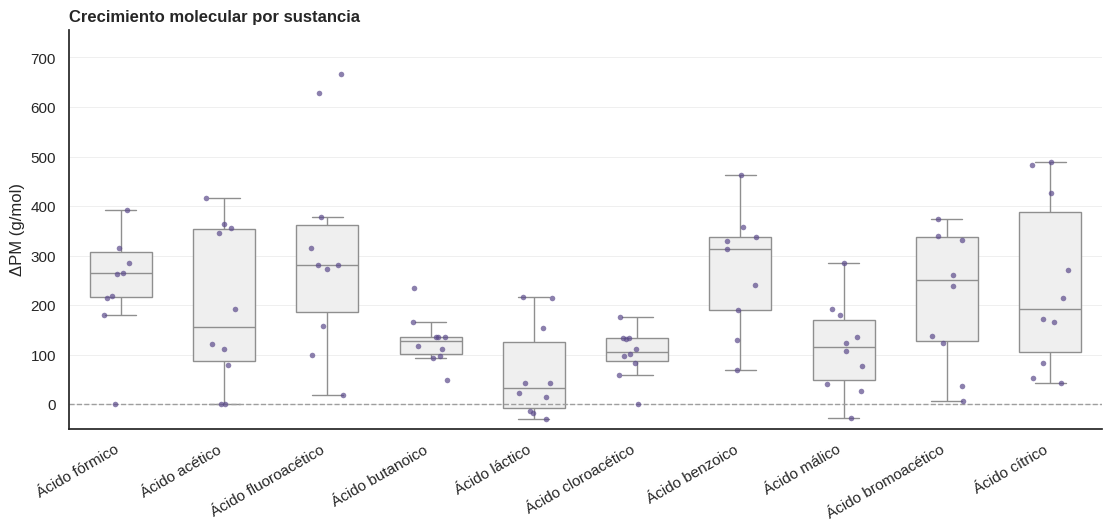

P(ΔPM > 0) = 0.91 de 99 reacciones
Sustancia
Ácido fórmico          264.0
Ácido acético          157.0
Ácido fluoroacético    280.0
Ácido butanoico        127.0
Ácido láctico           33.0
Ácido cloroacético     106.0
Ácido benzoico         313.0
Ácido málico           116.0
Ácido bromoacético     250.0
Ácido cítrico          193.0


In [ ]:
rx['ΔPM'] = rx['PM'] - rx['Sustancia'].map(sus.set_index('Sustancia')['PM'])
tope = rx['ΔPM'].quantile(0.97) * 1.2
fig, ax = plt.subplots(figsize=(11, 5.2), constrained_layout=True)
sns.boxplot(data=rx, x='Sustancia', y='ΔPM', order=ORDEN, color='#EFEFEF', fliersize=0, width=0.6, ax=ax)
sns.stripplot(data=rx[rx['ΔPM'] <= tope], x='Sustancia', y='ΔPM', order=ORDEN, color=COL_VAR['PM'],
              size=4, alpha=0.7, jitter=0.18, ax=ax)
ax.axhline(0, color=GRIS, ls='--', lw=1)
ax.set_ylim(min(rx['ΔPM'].min() * 1.15, -50), tope); ax.set_xlabel(''); ax.set_ylabel('ΔPM (g/mol)')
fuera = int((rx['ΔPM'] > tope).sum())
ax.set_title(f'Crecimiento molecular por sustancia')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
guardar(fig, '11_cambio_peso_molecular'); plt.show()
print(f"P(ΔPM > 0) = {(rx['ΔPM'] > 0).mean():.2f} de {rx['ΔPM'].notna().sum()} reacciones")
print(rx.groupby('Sustancia')['ΔPM'].median().reindex(ORDEN).round(0).to_string())

**Tipo de gráfica.** Diagrama de caja con puntos: distribución de una variable numérica por sustancia.

**Interpretación.** El 91 % de las reacciones (de 99) dan un producto más pesado que el ácido de partida, porque se forman ésteres y amidas que suman el fragmento del alcohol o la amina. El benzoico (+313 g/mol) y el fluoroacético (+280) tienen las medianas más altas; el láctico la más baja (+33), porque varias de sus reacciones son sales, complejos o reducciones que casi no cambian la masa.

### Gráfica 12. Frecuencia de cada familia de reacción: reacciones frente a obtenciones

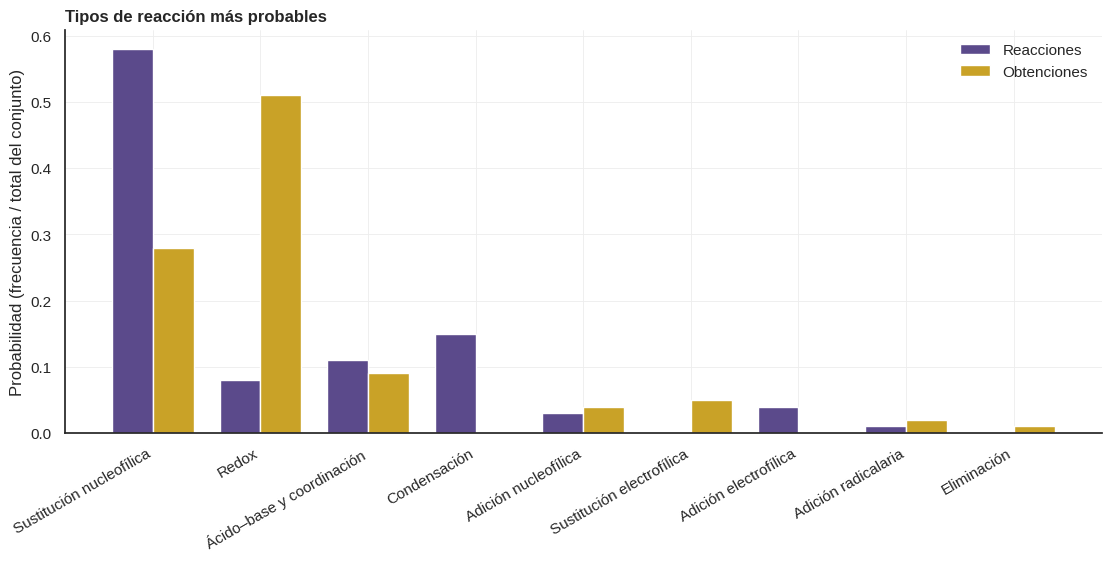

Conjunto                   Obtenciones  Reacciones
Tipo de reacción                                  
Sustitución nucleofílica            28          58
Redox                               51           8
Ácido–base y coordinación            9          11
Condensación                         0          15
Adición nucleofílica                 4           3
Sustitución electrofílica            5           0
Adición electrofílica                0           4
Adición radicalaria                  2           1
Eliminación                          1           0


In [ ]:
tabla = pd.crosstab(ambos['Tipo de reacción'], ambos['Conjunto'], normalize='columns')
orden = tabla.sum(axis=1).sort_values(ascending=False).index.tolist()
tabla = tabla.loc[orden]

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
x = np.arange(len(orden)); w = 0.38
for i, conj in enumerate(['Reacciones', 'Obtenciones']):
    ax.bar(x + (i - 0.5) * w, tabla[conj], width=w, color=COL_CONJ[conj], label=conj)
ax.set_xticks(x); ax.set_xticklabels(orden, rotation=30, ha='right')
ax.set_ylabel('Probabilidad (frecuencia / total del conjunto)'); ax.set_xlabel('')
ax.set_title('Tipos de reacción más probables'); ax.legend(frameon=False)
guardar(fig, '12_tipos_reaccion'); plt.show()
print(pd.crosstab(ambos['Tipo de reacción'], ambos['Conjunto']).loc[orden].to_string())

**Tipo de gráfica.** Gráfico de barras agrupadas: variable categórica (tipo de reacción) en dos grupos; se usan proporciones porque cada conjunto tiene su propio total.

**Interpretación.** Cada reacción se clasificó por su mecanismo principal en los tipos indicados por el profesor; las que no son reacciones orgánicas (neutralizaciones, sales y complejos metálicos) se agrupan como "Ácido–base y coordinación". Al **reaccionar**, domina la sustitución nucleofílica (58 %): el –COOH forma ésteres y amidas por sustitución nucleofílica en el acilo, y en los haloácidos un nucleófilo reemplaza al halógeno. Le sigue la condensación (15 %). Para **obtenerlos** domina el redox (51 %: oxidación de alcoholes y aldehídos, hidrogenación de dobles enlaces), seguido de la sustitución nucleofílica (28 %: hidrólisis de ésteres, amidas y haluros de acilo). La sustitución radicalaria no apareció en ninguna reacción.

### Gráfica 13. Probabilidad del medio de reacción

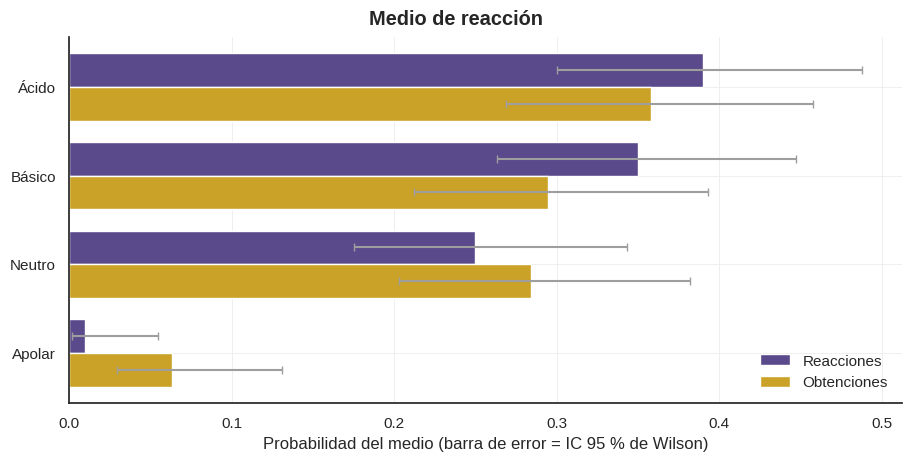

   Conjunto  Medio  n    P   lo   hi
Obtenciones  Ácido 34 0.36 0.27 0.46
Obtenciones Básico 28 0.29 0.21 0.39
Obtenciones Neutro 27 0.28 0.20 0.38
Obtenciones Apolar  6 0.06 0.03 0.13
 Reacciones  Ácido 39 0.39 0.30 0.49
 Reacciones Básico 35 0.35 0.26 0.45
 Reacciones Neutro 25 0.25 0.18 0.34
 Reacciones Apolar  1 0.01 0.00 0.05


In [ ]:
filas = []
for conj, g in ambos.groupby('Conjunto'):
    n_tot = g['Medio'].notna().sum()
    for m in MEDIOS:
        p, lo, hi = wilson((g['Medio'] == m).sum(), n_tot)
        filas.append(dict(Conjunto=conj, Medio=m, n=int((g['Medio'] == m).sum()), P=p, lo=lo, hi=hi))
res = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
y = np.arange(len(MEDIOS)); h = 0.38
for i, conj in enumerate(['Reacciones', 'Obtenciones']):
    t = res[res['Conjunto'] == conj].set_index('Medio').reindex(MEDIOS)
    ax.barh(y + (i - 0.5) * h, t['P'], height=h, color=COL_CONJ[conj], label=conj,
            xerr=[t['P'] - t['lo'], t['hi'] - t['P']], error_kw={'ecolor': GRIS, 'capsize': 3})
ax.set_yticks(y); ax.set_yticklabels(MEDIOS); ax.invert_yaxis(); ax.set_ylabel('')
ax.set_xlabel('Probabilidad del medio (barra de error = IC 95 % de Wilson)'); ax.legend(frameon=False)
fig.suptitle('Medio de reacción', fontweight='bold')
guardar(fig, '13_medio_reaccion'); plt.show()
print(res.round(2).to_string(index=False))

**Tipo de gráfica.** Barras horizontales agrupadas con barras de error, con IC 95 % de Wilson.

**Interpretación.** Medio ácido (0.39 en reacciones, 0.36 en obtenciones) y básico (0.35 y 0.29) son los más probables y sus IC se solapan. Ácido: esterificaciones de Fischer catalizadas por H⁺; básico: sustituciones de los haloácidos y saponificaciones. El medio apolar es raro (0.01 y 0.06). Las barras de error son el IC 95 % de Wilson.

### Gráfica 14. Relación sustancia × medio de reacción

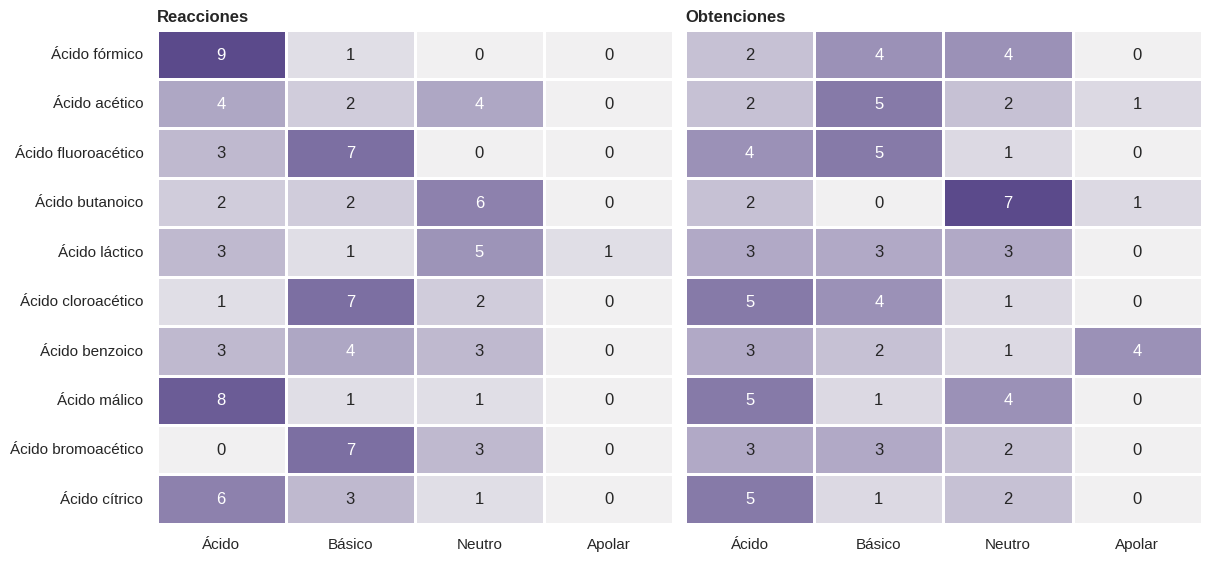

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, constrained_layout=True)
for ax, conj in zip(axs, ['Reacciones', 'Obtenciones']):
    t = pd.crosstab(ambos[ambos['Conjunto'] == conj]['Sustancia'], ambos[ambos['Conjunto'] == conj]['Medio'])
    t = t.reindex(index=ORDEN, columns=MEDIOS, fill_value=0)
    sns.heatmap(t, cmap=SEQ, annot=True, fmt='d', linewidths=0.8, linecolor='white', cbar=False, ax=ax)
    ax.set_title(conj); ax.set_xlabel(''); ax.set_ylabel('')
guardar(fig, '14_sustancia_medio'); plt.show()

**Tipo de gráfica.** Mapa de calor de una tabla de contingencia: cruza dos variables categóricas; el número de cada celda es la frecuencia.

**Interpretación.** El ácido fórmico (9) y el málico (8) reaccionan casi siempre en medio ácido. Los tres haloácidos (fluoro-, cloro- y bromoacético) reaccionan en medio básico en 7 de 10 casos: la base desprotona el ácido o el nucleófilo para la sustitución del halógeno. Para obtenerlos, el butanoico se forma sobre todo en medio neutro (7) y el benzoico es el único con varias obtenciones en medio apolar (4).

### Gráfica 15. Relación sustancia × tipo de reacción

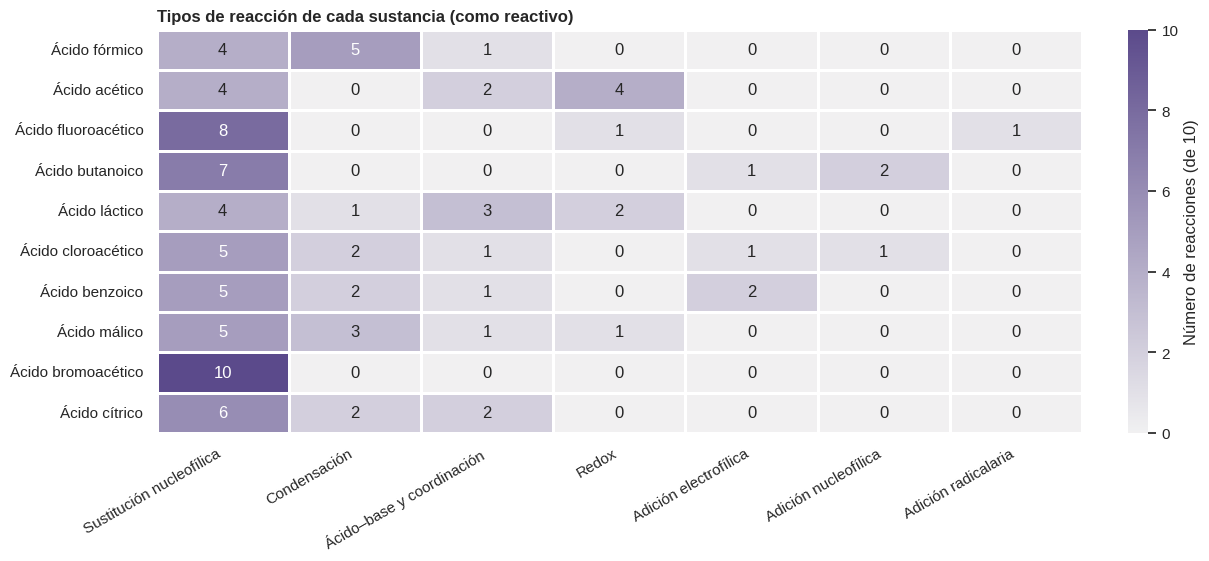

In [ ]:
t = pd.crosstab(rx['Sustancia'], rx['Tipo de reacción']).reindex(index=ORDEN, fill_value=0)
t = t[t.sum().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
sns.heatmap(t, cmap=SEQ, annot=True, fmt='d', linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Número de reacciones (de 10)'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Tipos de reacción de cada sustancia (como reactivo)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
guardar(fig, '15_sustancia_tipo'); plt.show()

**Tipo de gráfica.** Mapa de calor de una tabla de contingencia.

**Interpretación.** El ácido bromoacético reacciona por sustitución en 9 de 10 casos (el Br es un buen grupo saliente en el carbono α) y el cloroacético en 5. El butanoico (6), fluoroacético (5), benzoico (5) y málico (5) reaccionan sobre todo por acilación/esterificación. El fórmico es el más variado (adición 4, acilación 3), porque también actúa como reductor y fuente de CO.

### Gráfica 16. Burbujas: solvente frente a familia de reacción

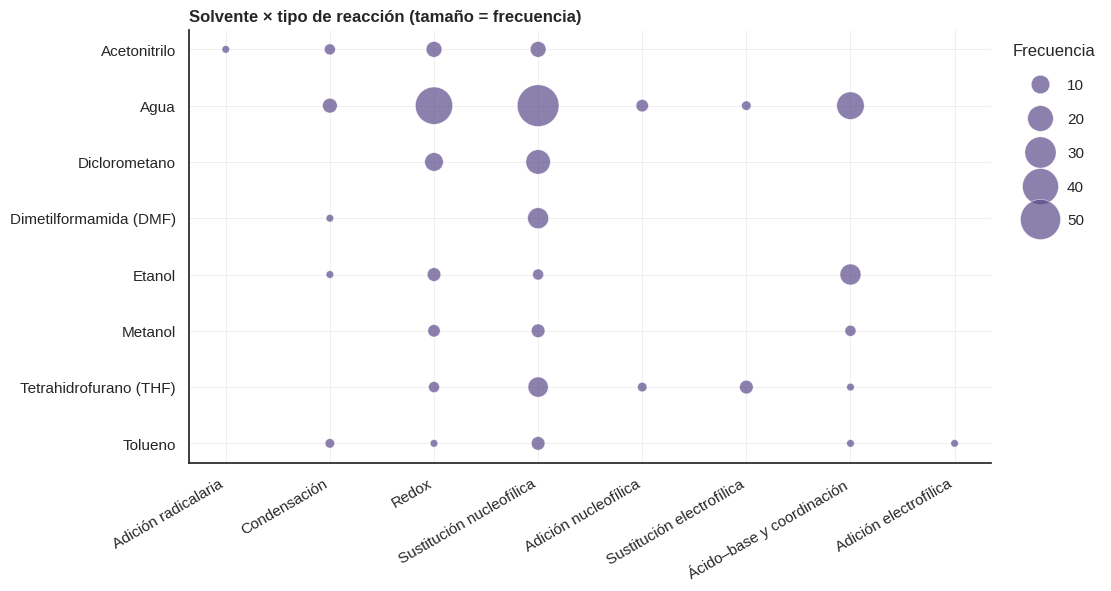

              Solvente          Tipo de reacción  n
                  Agua  Sustitución nucleofílica 54
                  Agua                     Redox 43
                  Agua Ácido–base y coordinación 23
         Diclorometano  Sustitución nucleofílica 18
Dimetilformamida (DMF)  Sustitución nucleofílica 13
Total de solventes distintos: 30


In [ ]:
filas = [rea, obt]
largo = pd.concat([d.melt(id_vars=['ID', 'Tipo de reacción'], value_vars=[c for c in d if c.startswith('Solvente')],
                          value_name='Solvente').dropna(subset=['Solvente']) for d in filas])
top = largo['Solvente'].value_counts().head(8).index
t = largo[largo['Solvente'].isin(top)].groupby(['Solvente', 'Tipo de reacción']).size().reset_index(name='n')
fig, ax = plt.subplots(figsize=(11, 5.8), constrained_layout=True)
sns.scatterplot(data=t, x='Tipo de reacción', y='Solvente', size='n', sizes=(30, 900), color=COL_VAR['PM'],
                alpha=0.7, edgecolor='white', legend='brief', ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Solvente × tipo de reacción (tamaño = frecuencia)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
ax.legend(title='Frecuencia', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False, labelspacing=1.3)
guardar(fig, '16_burbujas_solvente_tipo'); plt.show()
print(t.sort_values('n', ascending=False).head(5).to_string(index=False))
print('Total de solventes distintos:', largo['Solvente'].nunique())

**Tipo de gráfica.** Gráfico de burbujas en matriz (*Bubble Chart*): cruza dos variables categóricas y el área de la burbuja es la frecuencia

**Interpretación.** El **agua** es el solvente dominante: oxidación (31), «otras» (27), sustitución (24) e hidrólisis (14). Los ácidos de cadena corta y los hidroxiácidos son solubles en agua, y la hidrólisis necesita agua como reactivo. Los solventes orgánicos (DMF, THF, DCM) aparecen sobre todo en acilación, donde el agua hidrolizaría el agente acilante. 30 solventes distintos; se muestran los 8 más usados.

### Gráfica 17. Probabilidad de usar catalizador y de calentar, por sustancia

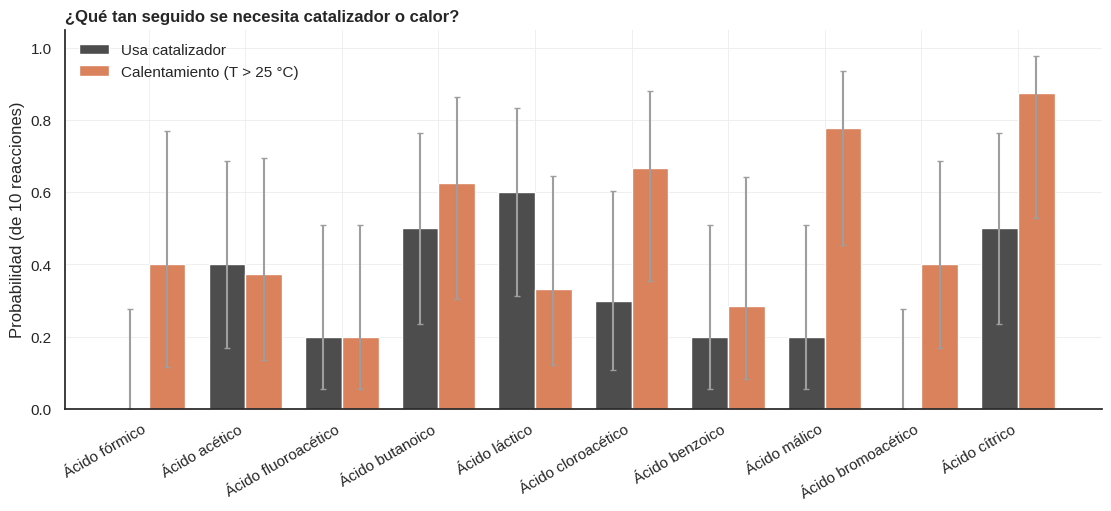

P(catalizador) = 0.29 (n = 100) | P(T > 25 °C) = 0.49 (n = 83)
P(catalizador | calor) = 0.41 (n = 41) | P(catalizador | sin calor) = 0.24 (n = 42)


In [ ]:
filas = []
for s_, g in rx.groupby('Sustancia'):
    for var, et in (('Usa catalizador', 'Usa catalizador'), ('Calor', 'Calentamiento (T > 25 °C)')):
        if var == 'Usa catalizador':
            serie = g['Usa catalizador']
        else:
            serie = g['T_max'].dropna() > 25
        p, lo, hi = wilson(int(serie.sum()), len(serie))
        filas.append(dict(Sustancia=s_, Variable=et, P=p, lo=lo, hi=hi))
t = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x = np.arange(len(ORDEN)); w = 0.38
for i, (et, col) in enumerate(zip(t['Variable'].unique(), [COL_SI['cat'], COL_SI['calor']])):
    s = t[t['Variable'] == et].set_index('Sustancia').reindex(ORDEN)
    ax.bar(x + (i - 0.5) * w, s['P'], width=w, color=col, label=et,
           yerr=[s['P'] - s['lo'], s['hi'] - s['P']], error_kw={'ecolor': GRIS, 'capsize': 2})
ax.set_xticks(x); ax.set_xticklabels(ORDEN, rotation=30, ha='right'); ax.set_xlabel('')
ax.set_ylim(0, 1.05); ax.set_ylabel('Probabilidad (de 10 reacciones)'); ax.legend(frameon=False)
ax.set_title('¿Qué tan seguido se necesita catalizador o calor?')
guardar(fig, '17_prob_catalizador_calor'); plt.show()
conT = rx.dropna(subset=['T_max'])
cal = conT['T_max'] > 25
print(f"P(catalizador) = {rx['Usa catalizador'].mean():.2f} (n = {len(rx)}) | P(T > 25 °C) = {cal.mean():.2f} (n = {len(conT)})")
print(f"P(catalizador | calor) = {conT.loc[cal, 'Usa catalizador'].mean():.2f} (n = {cal.sum()}) | P(catalizador | sin calor) = {conT.loc[~cal, 'Usa catalizador'].mean():.2f} (n = {(~cal).sum()})")

**Tipo de gráfica.** Barras agrupadas con barras de error: variables sí/no expresadas como proporción con su IC 95 % de Wilson.

**Interpretación.** El catalizador se usa en 29 % de las reacciones y el calentamiento en 49 % (de 83 con T). Con calentamiento el catalizador es más probable (0.41, n = 41) que sin él (0.24, n = 42), por ejemplo en esterificaciones catalizadas por ácido a reflujo. El fórmico y el bromoacético no usan catalizador en ninguna de sus 10 reacciones. Las barras de error son amplias por el n = 10 de cada sustancia.

### Gráficas 18 y 19. Interactivas (Plotly)

In [ ]:
d = rx.dropna(subset=['PM', 'Peb']).copy()
fig = px.scatter(d, x='PM', y='Peb', color='Tipo de reacción', hover_data=['Producto', 'Sustancia', 'ID', 'Medio'],
                 labels={'PM': UNIDAD['PM'], 'Peb': UNIDAD['Peb']}, height=550,
                 title='Productos: PM frente a Peb (pasa el cursor sobre los puntos)',
                 color_discrete_sequence=list(COL_VAR.values()))
fig.write_html(f'{CARPETA}/18_interactivo_PM_Peb.html'); fig.show()

fig2 = px.sunburst(rx.fillna({'Medio': 'Sin dato'}), path=['Sustancia', 'Medio', 'Tipo de reacción'], height=600,
                   title='Sustancia → medio → tipo de reacción', color_discrete_sequence=list(COL_VAR.values()))
fig2.write_html(f'{CARPETA}/19_interactivo_solar.html'); fig2.show()

**Tipo de gráfica.** Dispersión interactiva y diagrama solar: jerarquía de tres niveles categóricos leída del centro hacia afuera.

**Interpretación.** **Dispersión interactiva:** al pasar el cursor se identifica cada producto, lo que permite revisar los valores de Peb corregidos.

**Diagrama solar:** sustancia → medio → familia

## 4. Descarga de las figuras

In [ ]:
shutil.make_archive(CARPETA, 'zip', CARPETA)
if EN_COLAB:
    files.download(f'{CARPETA}.zip')
print('Figuras guardadas en', CARPETA)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Figuras guardadas en figuras_acidos
